# CoordinX — Exploratory Data Analysis (EDA)
**PRD Phase 2**: Analisis menyeluruh pola koordinasi pada dataset terstandarisasi (`RoySuryo`).

### Alur Analisis:
1. **Setup & Data Loading**
2. **Data Health & Missing Value Audit**
3. **Distribusi Aktivitas Akun**
4. **Distribusi Temporal & Deteksi Burst (WIB)**
5. **Kemiripan Narasi & Sinkronisasi Waktu (NLP)**
6. **Analisis Hashtag**
7. **Analisis Graf Interaksi (NetworkX)**

## 1. Setup & Data Loading

In [1]:
import os
import re
from collections import Counter
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import networkx as nx
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Set style
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
pd.set_option('display.max_columns', None)

# Resolve data path (lokal notebook vs root)
import os
candidate_paths = [
    '../data/processed/RoySuryo/standardized_data.csv',
    'data/processed/RoySuryo/standardized_data.csv',
    os.path.join(os.getcwd(), 'data/processed/RoySuryo/standardized_data.csv'),
    os.path.join(os.getcwd(), '../data/processed/RoySuryo/standardized_data.csv'),
    os.path.expanduser('~/Project/Project/Buzzer-Detection-/data/processed/RoySuryo/standardized_data.csv')
]
DATA_PATH = next((p for p in candidate_paths if os.path.exists(p)), None)
if DATA_PATH is None:
    raise FileNotFoundError("Dataset standardized_data.csv tidak ditemukan.")
df = pd.read_csv(DATA_PATH, dtype={'post_id': 'string', 'account_id': 'string', 'target_account_id': 'string'})
df_clean = df.drop_duplicates(subset=['post_id'], keep='first').copy()

print(f'✓ Data loaded: {len(df_clean)} posts, {df_clean["account_id"].nunique()} unique accounts')

✓ Data loaded: 1081 posts, 796 unique accounts


## 2. Data Health & Missing Value Audit

In [2]:
missing_data = df_clean.isnull().sum()
missing_report = pd.DataFrame({
    'Missing Values': missing_data,
    'Persentase (%)': (missing_data / len(df_clean) * 100).round(2)
})
display(missing_report[missing_report['Missing Values'] > 0].sort_values(by='Missing Values', ascending=False))

# Audit kelengkapan target relasi
target_check = df_clean.groupby('relation_type').agg(
    total_post=('post_id', 'count'),
    missing_target_post=('target_post_id', lambda x: x.isna().sum()),
    missing_target_account=('target_account_id', lambda x: x.isna().sum())
)
target_check['persentase_missing (%)'] = (target_check['missing_target_account'] / target_check['total_post'] * 100).round(2)
display(target_check)

,Missing Values,Persentase (%)
target_post_id,344,31.82
target_account_id,344,31.82
target_username,344,31.82
bio,325,30.06


,total_post,missing_target_post,missing_target_account,persentase_missing (%)
relation_type,,,,
original,344,344,344,100.0
quote,116,0,0,0.0
reply,621,0,0,0.0


## 3. Distribusi Aktivitas Akun

Total Akun: 796
Rata-rata postingan per akun: 1.36
Median: 1
Akun dengan tepat 1 post: 662 (83.2%)
Post terbanyak oleh satu akun: 29


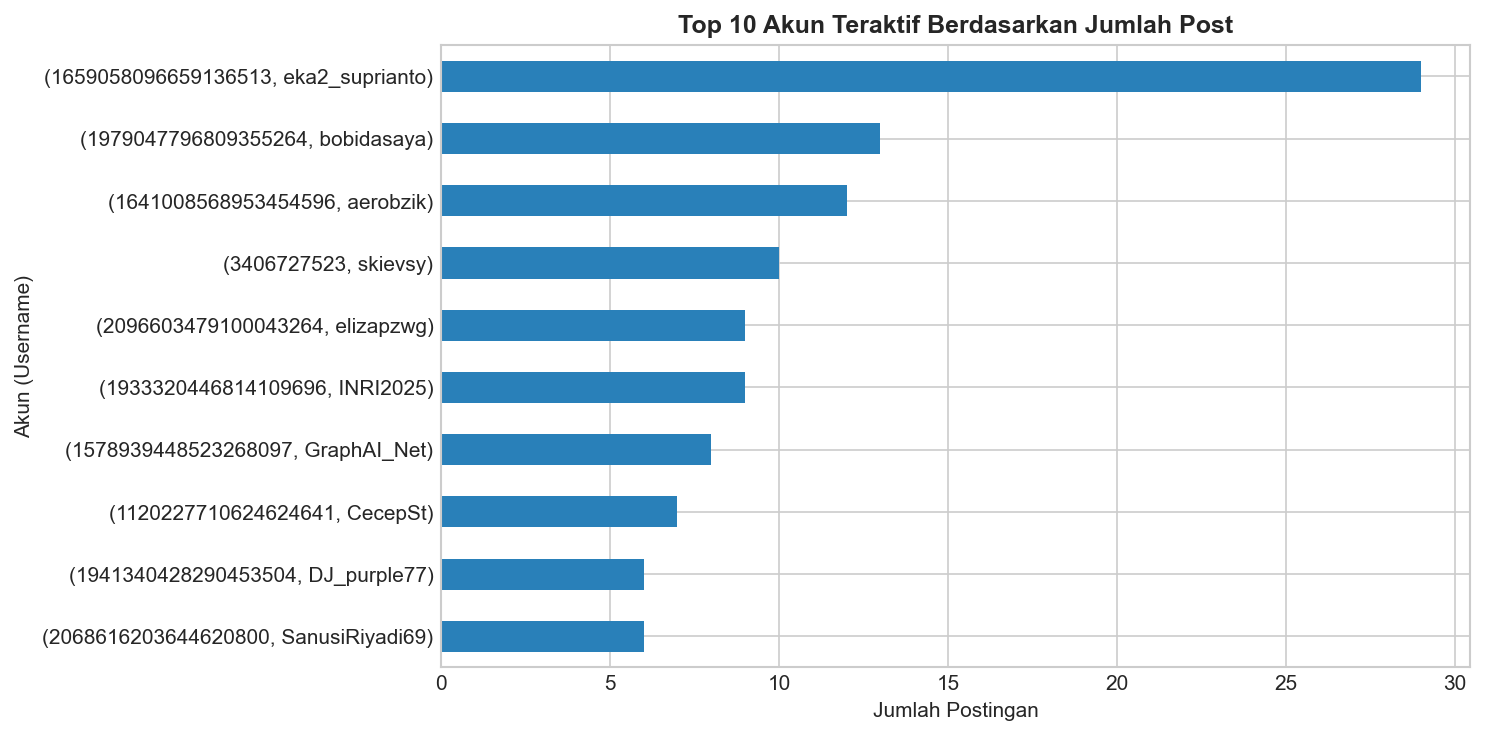

In [3]:
posts_per_acc = df_clean.groupby(['account_id', 'username'])['post_id'].nunique().sort_values(ascending=False)

print(f'Total Akun: {len(posts_per_acc)}')
print(f'Rata-rata postingan per akun: {posts_per_acc.mean():.2f}')
print(f'Median: {posts_per_acc.median():.0f}')
print(f'Akun dengan tepat 1 post: {(posts_per_acc == 1).sum()} ({(posts_per_acc == 1).sum()/len(posts_per_acc)*100:.1f}%)')
print(f'Post terbanyak oleh satu akun: {posts_per_acc.max()}')

# Visualisasi Top 10 Akun
plt.figure(figsize=(10, 5))
posts_per_acc.head(10).sort_values().plot(kind='barh', color='#2980b9')
plt.title('Top 10 Akun Teraktif Berdasarkan Jumlah Post', fontsize=12, fontweight='bold')
plt.xlabel('Jumlah Postingan')
plt.ylabel('Akun (Username)')
plt.tight_layout()
plt.show()

## 4. Distribusi Temporal & Deteksi Burst (WIB)

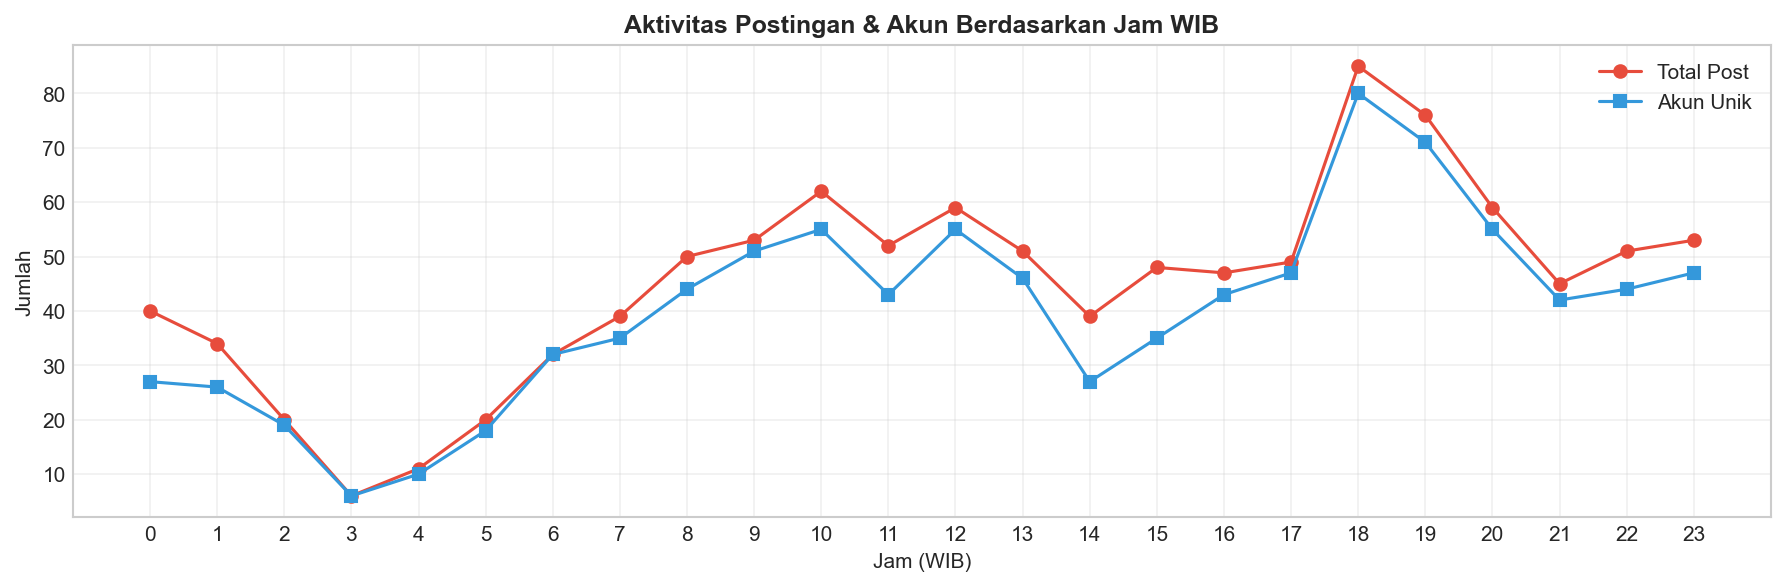

In [4]:
# Konversi waktu ke Asia/Jakarta (WIB)
df_clean['date'] = pd.to_datetime(df_clean['date'], utc=True, errors='coerce')
df_time = df_clean.dropna(subset=['date']).copy()
df_time['date_wib'] = df_time['date'].dt.tz_convert('Asia/Jakarta')
df_time['hour_wib'] = df_time['date_wib'].dt.hour

hourly_activity = df_time.groupby('hour_wib').agg(
    total_posts=('post_id', 'count'),
    unique_accounts=('account_id', 'nunique')
)

plt.figure(figsize=(12, 4))
plt.plot(hourly_activity.index, hourly_activity['total_posts'], marker='o', label='Total Post', color='#e74c3c')
plt.plot(hourly_activity.index, hourly_activity['unique_accounts'], marker='s', label='Akun Unik', color='#3498db')
plt.title('Aktivitas Postingan & Akun Berdasarkan Jam WIB', fontsize=12, fontweight='bold')
plt.xlabel('Jam (WIB)')
plt.ylabel('Jumlah')
plt.xticks(range(24))
plt.grid(alpha=0.3)
plt.legend()
plt.tight_layout()
plt.show()

=== 10 INTERVAL PALING TERSINKRONISASI (10 Menit) ===


,total_posts,unique_accounts
date_wib,,
2026-11-07 12:10:00+07:00,12,12
2026-11-06 20:20:00+07:00,11,11
2026-11-06 18:30:00+07:00,11,11
2026-11-07 08:40:00+07:00,10,10
2026-11-06 20:30:00+07:00,10,10
2026-11-06 19:30:00+07:00,11,9
2026-11-06 18:20:00+07:00,9,9
2026-11-07 18:20:00+07:00,10,9
2026-11-07 08:50:00+07:00,9,9


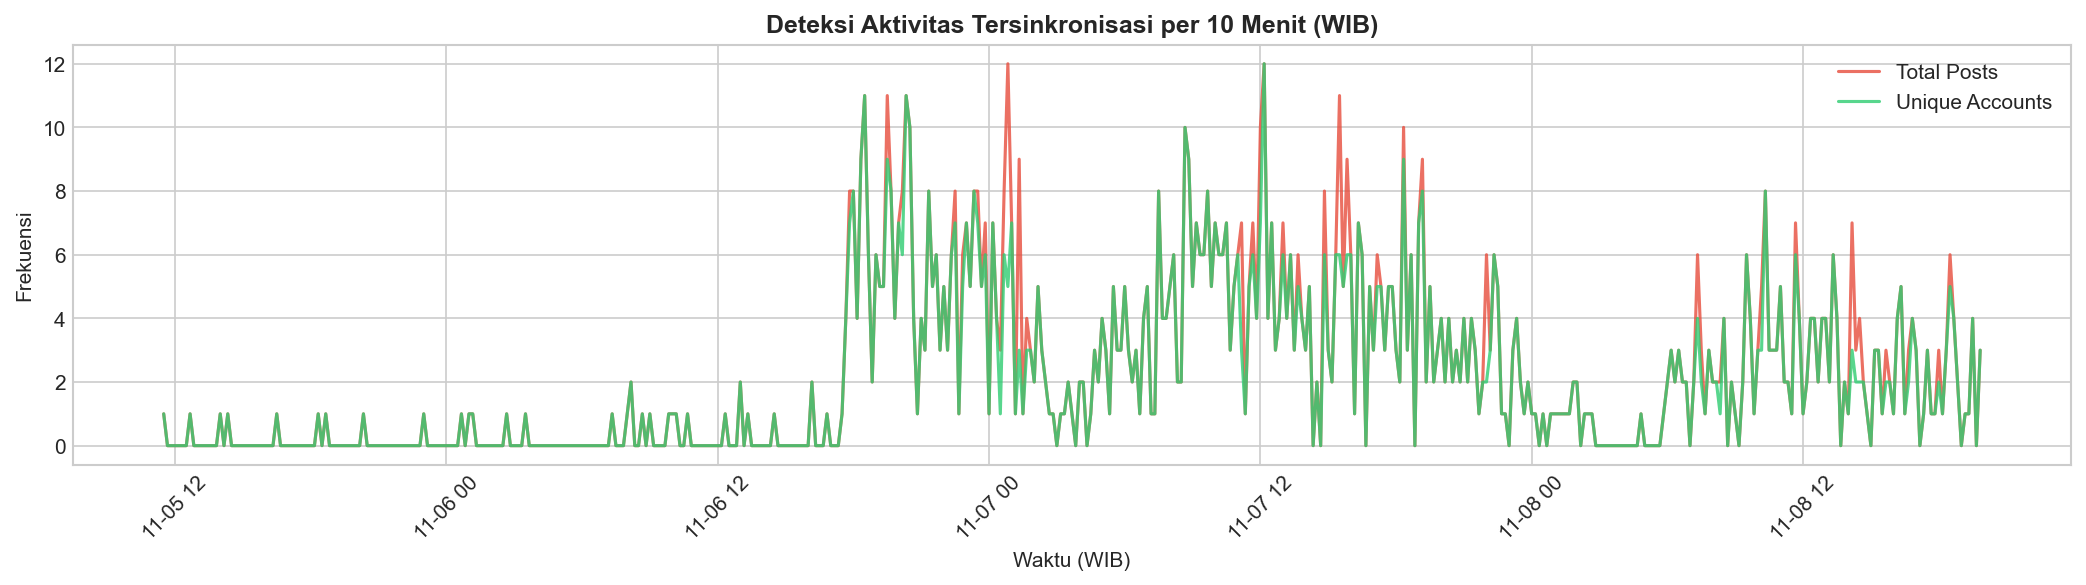

In [5]:
# Burst Detection: Resampling 10 Menit
df_time_indexed = df_time.set_index('date_wib')
burst_analysis = df_time_indexed.resample('10min').agg(
    total_posts=('post_id', 'nunique'),
    unique_accounts=('account_id', 'nunique')
)

top_synchronized = burst_analysis.sort_values(by='unique_accounts', ascending=False).head(10)
print('=== 10 INTERVAL PALING TERSINKRONISASI (10 Menit) ===')
display(top_synchronized)

plt.figure(figsize=(14, 4))
plt.plot(burst_analysis.index, burst_analysis['total_posts'], label='Total Posts', color='#e74c3c', alpha=0.8)
plt.plot(burst_analysis.index, burst_analysis['unique_accounts'], label='Unique Accounts', color='#2ecc71', alpha=0.8)
plt.title('Deteksi Aktivitas Tersinkronisasi per 10 Menit (WIB)', fontsize=12, fontweight='bold')
plt.xlabel('Waktu (WIB)')
plt.ylabel('Frekuensi')
plt.xticks(rotation=45)
plt.legend()
plt.tight_layout()
plt.show()

## 5. Kemiripan Narasi & Sinkronisasi Waktu (NLP)

In [6]:
# Bersihkan teks narasi (buang mention & URL)
df_analysis = df_clean.copy()
df_analysis['narrative'] = df_analysis['text'].astype(str).str.replace(r'https?://\S+', '', regex=True)
df_analysis['narrative'] = df_analysis['narrative'].str.replace(r'@\w+', '', regex=True).str.strip()
df_analysis['narrative_words'] = df_analysis['narrative'].str.split().str.len()

# Filter teks bermakna (min 4 kata)
df_narrative_long = df_analysis[df_analysis['narrative_words'] >= 4].reset_index(drop=True)
print(f'Post dengan narasi >= 4 kata: {len(df_narrative_long)} dari {len(df_analysis)}')

# TF-IDF + Cosine Similarity
vectorizer = TfidfVectorizer(ngram_range=(1, 2), min_df=1, max_features=4000)
tfidf_matrix = vectorizer.fit_transform(df_narrative_long['narrative'])
sim_matrix = cosine_similarity(tfidf_matrix)
np.fill_diagonal(sim_matrix, 0) # nolkan diri sendiri

print(f'Ukuran matriks kemiripan: {sim_matrix.shape}')
print(f'Kemiripan tertinggi antar-post: {sim_matrix.max():.4f}')

Post dengan narasi >= 4 kata: 1057 dari 1081
Ukuran matriks kemiripan: (1057, 1057)
Kemiripan tertinggi antar-post: 1.0000


In [7]:
# Pasangan postingan mirip dari akun BERBEDA dalam jendela waktu
accounts = df_narrative_long['username'].to_numpy()
dates = pd.to_datetime(df_narrative_long['date'], utc=True).to_numpy()

upper_tri = np.triu(np.ones(sim_matrix.shape, dtype=bool), k=1)
diff_accs = (accounts[:, None] != accounts[None, :])
high_sim = (sim_matrix >= 0.40)

rows, cols = np.where(upper_tri & diff_accs & high_sim)

pair_records = []
for r, c in zip(rows, cols):
    time_diff_min = abs(float((dates[r] - dates[c]) / np.timedelta64(1, 's'))) / 60.0
    pair_records.append({
        'account_1': accounts[r],
        'account_2': accounts[c],
        'similarity': round(float(sim_matrix[r, c]), 3),
        'time_diff_min': round(time_diff_min, 1),
        'text_1': df_narrative_long.iloc[r]['narrative'][:90],
        'text_2': df_narrative_long.iloc[c]['narrative'][:90]
    })

narrative_pairs_time = pd.DataFrame(pair_records).sort_values(by=['similarity', 'time_diff_min'], ascending=[False, True])
print(f'Total pasangan mirip antar-akun: {len(narrative_pairs_time)}')
display(narrative_pairs_time.head(15))


Total pasangan mirip antar-akun: 346


,account_1,account_2,similarity,time_diff_min,text_1,text_2
342,LuckyLaki24,benzema_aly,1.000,105.0,"Aksi berjongkok di ruang sidang bukanlah wujud ketulusan, melainkan operasi psikologis unt","Aksi berjongkok di ruang sidang bukanlah wujud ketulusan, melainkan operasi psikologis unt"
9,awikuchuz,CocoLatii,1.000,170.8,DASCO BEKING ROY SURYO\nDADCO .....\nASU !!,to jumianto..... ngefans roy suryo tibake 😁
18,CocoLatii,flaviusjoneus,1.000,218.2,to jumianto..... ngefans roy suryo tibake 😁,Kesurupan roy suryo ?
10,awikuchuz,flaviusjoneus,1.000,389.0,DASCO BEKING ROY SURYO\nDADCO .....\nASU !!,Kesurupan roy suryo ?
8,parjo4423939442,ArdieSuhardi321,1.000,595.8,WONG PALSU KOK DITUNJUKKAN....\n\nROY SURYO SINDIR JOKOWI USAI IJAZAH DIPERLIHATKAN DI RUANG,WONG PALSU KOK DITUNJUKKAN....\n\nROY SURYO SINDIR JOKOWI USAI IJAZAH DIPERLIHATKAN DI RUANG
7,parjo4423939442,ArdieSuhardi321,1.000,600.8,WONG PALSU KOK DITUNJUKKAN....\n\nROY SURYO SINDIR JOKOWI USAI IJAZAH DIPERLIHATKAN DI RUANG,WONG PALSU KOK DITUNJUKKAN....\n\nROY SURYO SINDIR JOKOWI USAI IJAZAH DIPERLIHATKAN DI RUANG
5,parjo4423939442,ArdieSuhardi321,1.000,609.1,WONG PALSU KOK DITUNJUKKAN....\n\nROY SURYO SINDIR JOKOWI USAI IJAZAH DIPERLIHATKAN DI RUANG,WONG PALSU KOK DITUNJUKKAN....\n\nROY SURYO SINDIR JOKOWI USAI IJAZAH DIPERLIHATKAN DI RUANG
4,parjo4423939442,ArdieSuhardi321,1.000,610.5,WONG PALSU KOK DITUNJUKKAN....\n\nROY SURYO SINDIR JOKOWI USAI IJAZAH DIPERLIHATKAN DI RUANG,WONG PALSU KOK DITUNJUKKAN....\n\nROY SURYO SINDIR JOKOWI USAI IJAZAH DIPERLIHATKAN DI RUANG
104,fjrwo,vandy_46,1.000,1117.3,roy suryo be like:,Roy Suryo be like:
116,syedbry64190,adryanqyg2c,0.967,104.3,"Kalau miskin dan kelaparan, ke mana harus mengadu? Ini pertanyaan serius.\n\nSarapan &gt; Ti",Hukum jangan diganti dengan emosi massa. Bahaya kalau begini terus.\n\nSarapan &gt; Tifa &gt


## 6. Analisis Hashtag

Total pemakaian hashtag: 238
Jumlah hashtag unik: 94


,Hashtag,Frekuensi
0,#2026mamavote,18
1,#roysuryo,14
2,#jokowi,13
3,#aksirakyatbelanegara,12
4,#pln50rbcuma40rb,12
5,#kamibersamaprabowo,12
6,#gratisnaikkrl,11
7,#ijazahjokowi,10
8,#desakprabowotangkapjokowi,10
9,#happiest_mv_streaming,8


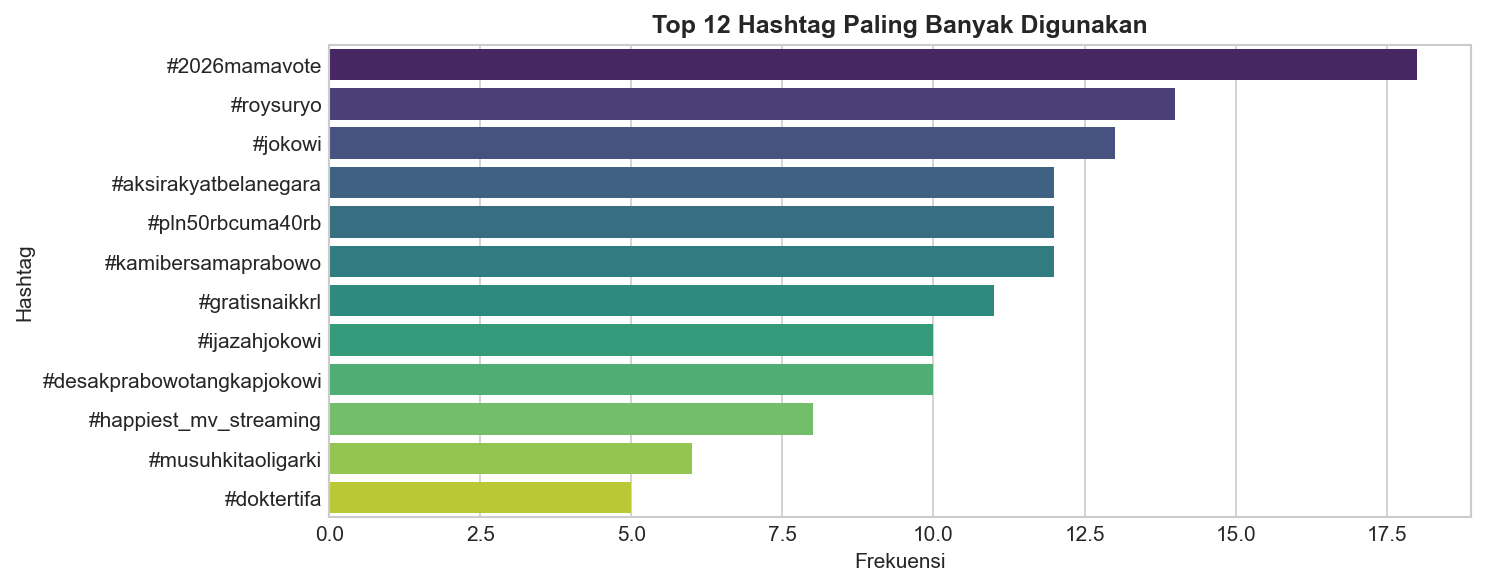

In [8]:
all_tags = [tag.lower() for sub in df_clean['text'].astype(str).str.findall(r'#\w+') for tag in sub]
tag_counts = Counter(all_tags)

print(f'Total pemakaian hashtag: {len(all_tags)}')
print(f'Jumlah hashtag unik: {len(tag_counts)}')

top_tags_df = pd.DataFrame(tag_counts.most_common(12), columns=['Hashtag', 'Frekuensi'])
display(top_tags_df)

plt.figure(figsize=(10, 4))
sns.barplot(data=top_tags_df, y='Hashtag', x='Frekuensi', hue='Hashtag', palette='viridis', legend=False)
plt.title('Top 12 Hashtag Paling Banyak Digunakan', fontsize=12, fontweight='bold')
plt.tight_layout()
plt.show()


## 7. Analisis Graf Interaksi (NetworkX)

In [9]:
# Ekstraksi relasi interaksi reply & quote
interaction_edges = df_clean[
    df_clean['relation_type'].isin(['reply', 'quote'])
    & df_clean['target_account_id'].notna()
].copy()

# Hindari self-loop (reply ke diri sendiri)
interaction_edges = interaction_edges[interaction_edges['account_id'] != interaction_edges['target_account_id']]

# Bangun Directed Graph (G)
G = nx.DiGraph()
for _, row in interaction_edges.iterrows():
    src = str(row['account_id'])
    dst = str(row['target_account_id'])
    G.add_edge(src, dst, relation_type=row['relation_type'])

print(f'Jumlah Node (Akun Terlibat): {G.number_of_nodes()}')
print(f'Jumlah Edge (Relasi Interaksi): {G.number_of_edges()}')

# Pemetaan akun ke username
username_map = dict(zip(df_clean['account_id'].astype(str), df_clean['username']))
if 'target_username' in df_clean.columns:
    target_map = dict(zip(df_clean['target_account_id'].dropna().astype(str), df_clean['target_username'].dropna()))
    username_map.update(target_map)

Jumlah Node (Akun Terlibat): 878
Jumlah Edge (Relasi Interaksi): 695


In [10]:
# Analisis In-Degree (Akun Sasaran) vs Out-Degree (Akun Penyerang/Inisiator)
in_deg = dict(G.in_degree())
out_deg = dict(G.out_degree())

centrality_df = pd.DataFrame({
    'account_id': list(G.nodes()),
    'username': [username_map.get(n, n) for n in G.nodes()],
    'in_degree': [in_deg[n] for n in G.nodes()],
    'out_degree': [out_deg[n] for n in G.nodes()],
    'pagerank': list(nx.pagerank(G, alpha=0.85).values())
})

print('=== TOP 10 AKUN PALING BANYAK DITARGET (In-Degree) ===')
display(centrality_df.sort_values(by='in_degree', ascending=False).head(10))

print('\n=== TOP 10 AKUN PALING AGRESIF MEMBALAS/MENGUTIP (Out-Degree) ===')
display(centrality_df.sort_values(by='out_degree', ascending=False).head(10))

=== TOP 10 AKUN PALING BANYAK DITARGET (In-Degree) ===

=== TOP 10 AKUN PALING AGRESIF MEMBALAS/MENGUTIP (Out-Degree) ===


,account_id,username,in_degree,out_degree,pagerank
372,2002820059648212992,olaolelaoo,22,0,0.012102
114,1389107518702374915,suncomeinrain,22,0,0.012620
475,3007567602,netizenledger,18,0,0.011593
206,1502822366946402304,DokterTifa,11,0,0.006440
331,1894088638180573184,yappingfess,10,0,0.006756
17,1749698965539553280,regar_op0sisi,10,0,0.004475
92,1003546165105704962,DedynurPalakka,10,0,0.005970
40,1759100655783043072,tham878,10,0,0.005442
67,121640063,RadioElshinta,9,0,0.005019
117,1745265761416056832,indepenSumatera,9,0,0.005199


,account_id,username,in_degree,out_degree,pagerank
180,1659058096659136513,eka2_suprianto,1,25,0.001316
6,1979047796809355264,bobidasaya,0,11,0.000711
155,2096603479100043264,elizapzwg,0,8,0.000711
239,1933320446814109696,INRI2025,0,7,0.000711
46,1120227710624624641,CecepSt,0,7,0.000711
134,1735636779192233984,sayno_KKN,0,5,0.000711
48,310722875,gimball_5057pa,0,5,0.000711
175,2068616203644620800,SanusiRiyadi69,0,5,0.000711
770,1819051650746925056,herma43884,0,5,0.000711
103,1941340428290453504,DJ_purple77,0,5,0.000711


Total Klaster Terpisah: 193
Ukuran Klaster Terbesar: 323 akun
Hub utama klaster: @olaolelaoo (In-degree: 22)


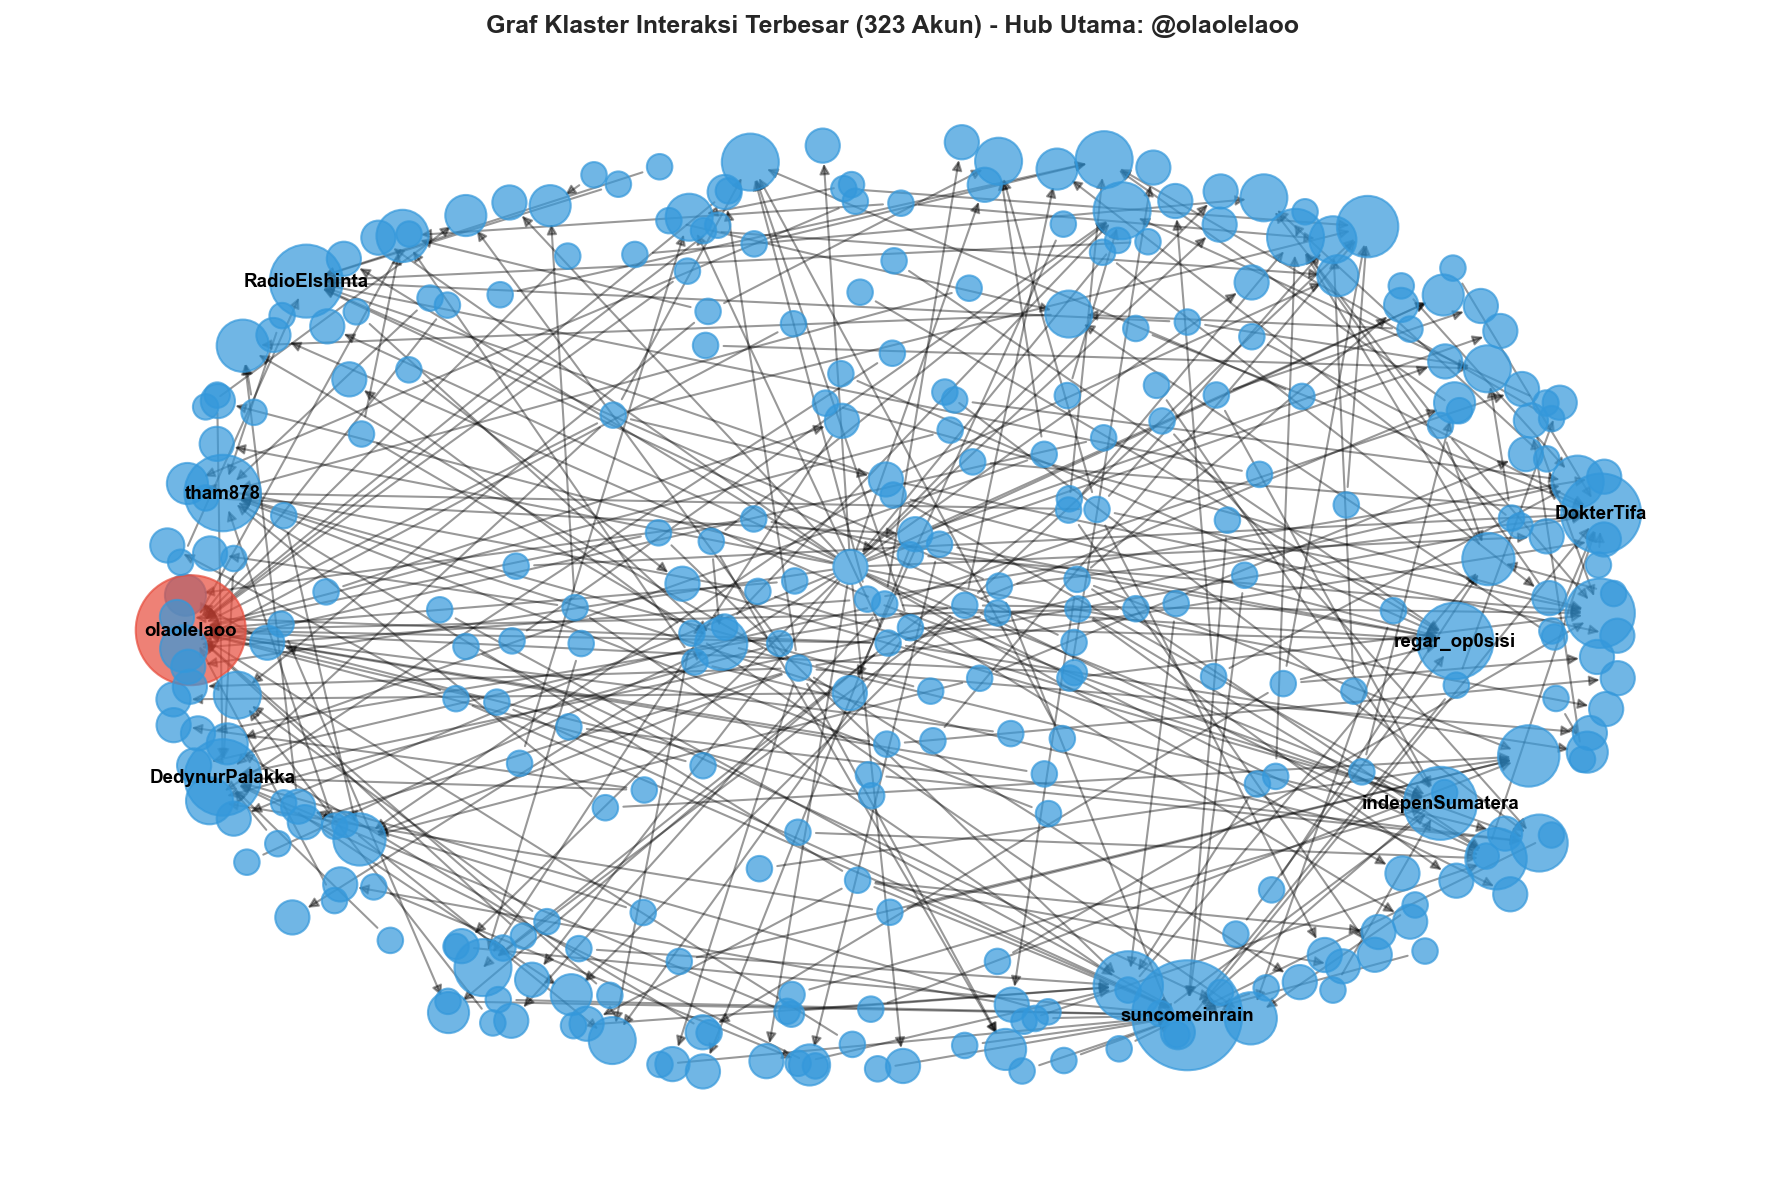

In [11]:
# Analisis Klaster (Weakly Connected Components)
wcc = sorted(list(nx.weakly_connected_components(G)), key=len, reverse=True)
print(f'Total Klaster Terpisah: {len(wcc)}')
print(f'Ukuran Klaster Terbesar: {len(wcc[0])} akun')

# Subgraph Klaster Terbesar
largest_comp = wcc[0]
G_sub = G.subgraph(largest_comp).copy()

# Deteksi Hub Utama secara dinamis
hub_node = max(dict(G_sub.in_degree()), key=dict(G_sub.in_degree()).get)
print(f'Hub utama klaster: @{username_map.get(hub_node, hub_node)} (In-degree: {G_sub.in_degree(hub_node)})')

# Visualisasi Subgraph Klaster Utama
plt.figure(figsize=(12, 8))
pos = nx.spring_layout(G_sub, seed=42, k=0.5)
node_sizes = [150 + G_sub.in_degree(n) * 120 for n in G_sub.nodes()]
node_colors = ['#e74c3c' if n == hub_node else '#3498db' for n in G_sub.nodes()]

nx.draw_networkx_nodes(G_sub, pos, node_size=node_sizes, node_color=node_colors, alpha=0.7)
nx.draw_networkx_edges(G_sub, pos, arrows=True, alpha=0.4, arrowsize=10)

# Beri label akun top 8
top_nodes = sorted(dict(G_sub.in_degree()).items(), key=lambda x: x[1], reverse=True)[:8]
labels = {n: username_map.get(n, n) for n, _ in top_nodes}
nx.draw_networkx_labels(G_sub, pos, labels=labels, font_size=9, font_weight='bold')

plt.title(f'Graf Klaster Interaksi Terbesar ({len(largest_comp)} Akun) - Hub Utama: @{username_map.get(hub_node, hub_node)}', fontsize=12, fontweight='bold')
plt.axis('off')
plt.tight_layout()
plt.show()